**David Granados González**

*All the content of the excersices was made by me and some were **enhanced** with AI (for example the answer for EX3)*

# Workbook 1 · Run smaller circuits and recover an observable

**Allow 90–120 minutes**, including eight exercises and discussion.
Computations run locally without an account or QPU. Basic Python arrays
and an introductory knowledge of quantum circuits are enough.

Follow one four-qubit circuit from a requested observable to twelve
two-qubit experiment settings and one reconstructed answer. Each step
explains the quantities you will later use to improve a planner.

**Scope:** this circuit is small enough for ordinary classical simulation.
We use it to check reconstruction
and compare execution plans under a specified width and shot budget.
These experiments do not demonstrate quantum advantage. See
[example scope](planner-prompt.md#what-this-example-establishes) for the classical checks
and the limits of the comparisons.

**How to work:** complete examples are labeled. Exercise functions
initially return None, and their checks report **Pending**. Later
examples run with the exercises left blank. Replace each None when
ready and write in the response spaces.
Save your own copy. Hints appear below each task.

Automatic checks test calculations. Use the hints and worked examples to
check your approach, and discuss your written reasoning with a partner or
instructor when possible.

## Before you run this workbook

Extract the **whole ZIP** and keep this notebook beside the `python` folder.
Use Python 3.12. Open a terminal in the extracted folder and create an environment:

**Windows PowerShell**
```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r python/requirements.txt
.\.venv\Scripts\python.exe -m jupyterlab
```

**macOS or Linux**
```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install -r python/requirements.txt
.venv/bin/python -m jupyterlab
```

In JupyterLab, open this notebook and choose its Python kernel. Select a cell
and press **Shift+Enter** to run it and move to the next. Markdown cells explain
the work; code cells perform it. Double-click a response cell to edit your explanation.
Use **Kernel → Restart Kernel and Run All Cells** for a clean run.
The saved outputs show the worked examples. Exercise answers are deliberately blank;
`Pending` means there is still an answer for you to supply.

Installation needs internet; the experiments use local Aer simulation and need
no IBM account or token. This notebook creates its own circuit. Its sampling cell writes a `results`
folder beside the notebook. Rerun that cell to create those files on your
machine; they are not extra downloads.

If an import fails, check `import sys; print(sys.executable)` in a code cell:
the kernel must use the environment where you installed the requirements.
Run `python/check_environment.py` with that environment's Python for a short
diagnostic. If the package cannot be found, start Jupyter from the extracted
folder and keep the `python` folder in place. Additional help and a file guide are in
[python/README.md](python/README.md).


In [2]:
from pathlib import Path
import json
from dataclasses import replace
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.circuit.library import RZZGate
from qiskit.quantum_info import SparsePauliOp, PauliList, Statevector
from qiskit_addon_cutting import (
    partition_problem, generate_cutting_experiments,
    reconstruct_expectation_values,
)
from qiskit_addon_cutting.qpd import QPDBasis
from qiskit_addon_cutting.utils.simulation import ExactSampler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "python" / "wqcc_planner" / "engine.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Extract the whole package and start Jupyter in its root folder.")
PYTHON_TOOLS = ROOT / "python"
if str(PYTHON_TOOLS) not in sys.path:
    sys.path.insert(0, str(PYTHON_TOOLS))
from wqcc_planner.instances import Instance, HardwareProfile
from wqcc_planner.engine import plan, execute, InfeasiblePlan

def write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    def convert(item):
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, np.ndarray):
            return item.tolist()
        raise TypeError(type(item).__name__)
    path.write_text(json.dumps(value, indent=2, default=convert,
                               allow_nan=False) + "\n", encoding="utf-8")

SEED = 20261001
progress = {f"E{i}": "Pending" for i in range(1, 9)}
def report(exercise, status):
    progress[exercise] = status
    print(f"{exercise}: {status}")

def show_circuit(circuit, title):
    print(title)
    figure = circuit.draw("mpl", fold=-1)
    display(figure)
    plt.close(figure)

print("WQCC planner materials loaded.")
print({name: metadata.version(name)
       for name in ["qiskit", "qiskit-addon-cutting", "qiskit-aer"]})
print("Eight exercises pending. Running examples does not complete them.")

WQCC planner materials loaded.
{'qiskit': '2.5.2', 'qiskit-addon-cutting': '0.10.0', 'qiskit-aer': '0.17.2'}
Eight exercises pending. Running examples does not complete them.


## 1. What answer are we asking for? · 10 minutes

An **observable** specifies a quantity to measure. For $Z_1Z_2$, measure
qubits 1 and 2 in the Z basis and multiply their values. Bit 0 represents
+1; bit 1 represents −1. Their product is +1 for matching bits and −1 for
different bits.

A **shot** is one fresh circuit execution and its measurement record.
The expectation $\langle Z_1Z_2\rangle$ is the mean score over the outcome
distribution. A finite collection of shots estimates that mean.

Qiskit's Pauli strings put qubit 0 on the **right**. Thus **IZZI** means
$I_3Z_2Z_1I_0$. Identity factors say those qubits do not enter this score.

In [3]:
# Illustrative measurement records for the worked example.
paired_bits = np.array([[0,0], [0,1], [1,0], [1,1]])
parity_scores = 1 - 2 * (paired_bits.sum(axis=1) % 2)
display(pd.DataFrame({"q1 bit": paired_bits[:,0], "q2 bit": paired_bits[:,1],
                      "Z1 times Z2 score": parity_scores}))
print("Average of these four illustrative scores:", parity_scores.mean())

,q1 bit,q2 bit,Z1 times Z2 score
0,0,0,1
1,0,1,-1
2,1,0,-1
3,1,1,1


Average of these four illustrative scores: 0.0


### Exercise 1 · Score a Z observable

Implement **student_z_scores(records, qubits)**. Each row is one shot;
columns are explicitly **q0, q1, q2, ...**, unlike the printed Pauli
string. Return one +1/−1 score per row for the selected columns. Assume
valid bit records and distinct, valid column indices. Do not average yet.

**Response:** Which columns correspond to IZZI? Why would summing the
two individual Z expectations answer a different question?

> Your explanation:
>|ZZ| is read right to left: $I_3\,Z_2\,Z_1\,I_0$, so the score uses columns 1 and 2 (q1 and q2); columns 0 and 3 are identity factors and are ignored. The score of one shot i $(-1)^{b_1\oplus b_2}$.
> ...

<details><summary>Hint</summary>
Count selected 1 bits in each row. Even parity means +1. An empty
selection represents the identity and always scores +1.
</details>

In [ ]:
def student_z_scores(records, qubits):
    records = np.asarray(records, dtype=int)
    qubits = list(qubits)
    if not qubits:
        return np.ones(records.shape[0], dtype=int)
    parity = records[:, qubits].sum(axis=1) % 2 #paridad de los bits seleccionados
    return 1 - 2*parity  # TODO: one score per row.

ex1_probe = np.array([[0,0,0,0], [0,1,0,1], [1,1,1,0], [1,0,1,1]])
ex1_answer = student_z_scores(ex1_probe, [1,2])
if ex1_answer is None:
    report("E1", "Pending: implement student_z_scores") #erroes
else:
    assert np.array_equal(ex1_answer, [1,-1,1,-1])
    assert np.array_equal(student_z_scores(ex1_probe, []), np.ones(4))
    assert np.array_equal(student_z_scores(ex1_probe, [0]), [1,1,-1,-1])
    report("E1", "Calculation checks passed: review your written explanation")

E1: Calculation checks passed: review your written explanation


## 2. Locate the boundary interaction · 10 minutes

Start in $|0000\rangle$. Apply H on every qubit, two interactions within
{0,1} and {2,3}, then an RZZ interaction connecting q1 and q2. Finally,
rotate each qubit around X. All angles are in radians.

We permit **two physical qubits per experiment**, ask for IZZI, and
spend **12,000 physical shots across the request**. Direct four-qubit
execution does not satisfy that width limit.

Fragment **A contains q0 and q1**; **B contains q2 and q3**. A fragment
is a group of wires together with the local circuit on them.

Original circuit; target Z1 Z2


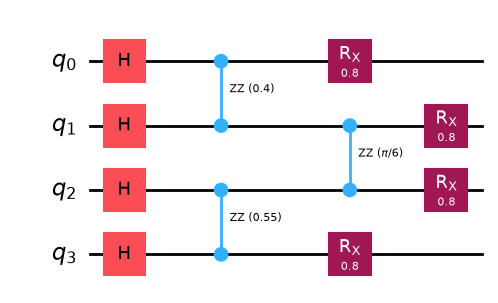

In [7]:
def make_worked_circuit(theta=np.pi/6):
    circuit = QuantumCircuit(4)
    circuit.h(range(4))
    circuit.rzz(0.4, 0, 1)
    circuit.rzz(0.55, 2, 3)
    circuit.rzz(theta, 1, 2)
    circuit.rx(0.8, range(4))
    return circuit

theta = np.pi/6
qc = make_worked_circuit(theta)
target = SparsePauliOp.from_list([("IZZI", 1.0)])
labels = ["A","A","B","B"]
instance = Instance("workbook-one-rzz", qc, target, max_width=2,
                    shots=12000, hardware=HardwareProfile(),
                    seed=SEED, family="teaching",
                    metadata={"purpose": "one crossing RZZ gate"})
show_circuit(qc, "Original circuit; target Z1 Z2")

### Exercise 2 · Find the boundary

Implement **student_crossing_indices(circuit, partition_labels)**.
Return instruction indices for two-qubit gates whose wires have
different partition labels. Do not hard-code a gate name or index.
Assume one- and two-qubit operations.

**Response:** Which interaction stays in A, which stays in B, and which
crosses? How would assigning all four wires to A change the answer?

> Your explanation: Considering a,a,b,b instruction 4, rzz(0.4) on (q0,q1) stays in A
instruction 5 rzz(0.55) on (q2,q3) stays in B
6 rzz($theta$) on (q1,q2) crosses

If you put all four qubits in one group, no gates need to be cut. But that group has 4 qubits, and the device only fits 2, so the plan can’t run. Cutting is the price you pay to make the circuit fit.

<details><summary>Hint</summary>
Iterate over circuit.data. For a wire q, circuit.find_bit(q).index gives
its original index. Compare labels only for two-qubit instructions.
</details>

In [ ]:
def student_crossing_indices(circuit, partition_labels):
    crossing = []
    for index, instruction in enumerate(circuit.data):#iterando
        wires = [circuit.find_bit(q).index for q in instruction.qubits]
        if len(wires) == 2 and partition_labels[wires[0]] != partition_labels[wires[1]]:
            crossing.append(index)
    return crossing #cuantas cruzan 

ex2_answer = student_crossing_indices(qc, labels)
if ex2_answer is None:
    report("E2", "Pending: identify boundary-crossing instructions")
else:
    assert ex2_answer == [6]
    assert student_crossing_indices(qc, ["A"]*4) == []
    assert student_crossing_indices(qc, ["A","B","A","B"]) == [4,5,6]
    report("E2", "Calculation checks passed: review your partition explanation")

E2: Calculation checks passed: review your partition explanation


### A diagnostic: deleting a gate changes the question

The next cell computes the ideal full-circuit answer and the answer
after removing the boundary gate. These **diagnostic references** let
us check the effect of that interaction. They remain outside the planner:
its decisions and estimates must use only the supplied inputs and
allocated measurements.

A valid cutting decomposition must account for the interaction's effect.

In [9]:
diagnostic_reference = float(
    Statevector.from_instruction(qc).expectation_value(target).real)
deleted = qc.copy()
del deleted.data[6]
deleted_reference = float(
    Statevector.from_instruction(deleted).expectation_value(target).real)
display(pd.Series({"original ideal answer": diagnostic_reference,
                   "answer after deleting the gate": deleted_reference}))
# Neither diagnostic is passed to plan() or execute().

original ideal answer             0.443207
answer after deleting the gate    0.000000
dtype: float64

**An independent classical check.** This particular circuit is simple
enough to solve with a formula. Let $\alpha=0.4$ and $\delta=0.55$ be the
two internal RZZ angles, $\theta=\pi/6$ the boundary angle, and $\beta=0.8$
the final RX angle on every qubit. Its ideal expectation is

$$\langle Z_1Z_2\rangle=
\sin\theta\,\cos\beta\,\sin\beta\,
(\cos\alpha+\cos\delta)\approx0.4432073161.$$

Setting $\theta=0$ removes the boundary interaction and gives zero.
The formula helps us check the experiment; it is not the planner's
returned estimate. Our task here is to build and evaluate the smaller
measurement experiments. The derivation is in
[example scope](planner-prompt.md#what-this-example-establishes).

## 3. The addon gives us local recipes · 15 minutes

**qiskit-addon-cutting** supplies decompositions, experiment generation,
cut finding, and reconstruction. Its local-operation decomposition of
RZZ specifies the smaller experiments and the coefficients needed to
recover the original observable.

A **recipe** specifies a boundary action in A, an action in B, and a
signed coefficient. Let $r$ label a recipe row. The symbols
$\mathcal A_r,\mathcal B_r$ describe local actions. The tensor product
$\mathcal A_r\otimes\mathcal B_r$ means each acts on its own subsystem.
The outer product $|u\rangle\langle v|$ instead constructs an operator
from two state vectors.

**I** inserts nothing; **Z** is a Pauli gate; **S** is diag(1,i), and
**Sdg** is its inverse. **Mz** means measure Z at the boundary, continue
the circuit, and include its recorded sign in the final score. The
signed measurement map is bookkeeping for a physical measurement,
not itself an ordinary trace-preserving channel.

In [10]:
# Worked example: inspect the actual addon basis in its RAW order.
basis = QPDBasis.from_instruction(RZZGate(theta))
operation_names = {"qpd_measure": "Mz", "sdg": "Sdg", "s": "S", "z": "Z"}
def local_recipe(operations):
    return " then ".join(operation_names.get(op.name, op.name)
                         for op in operations) or "I"

raw_recipe_table = pd.DataFrame([
    {"raw index (0-based)": r, "A boundary": local_recipe(pair[0]),
     "B boundary": local_recipe(pair[1]), "coefficient": float(weight)}
    for r, (weight, pair) in enumerate(zip(basis.coeffs, basis.maps))
])
display(raw_recipe_table)
print("gamma =", basis.kappa, "; gamma squared =", basis.overhead)

,raw index (0-based),A boundary,B boundary,coefficient
0,0,I,I,0.933013
1,1,Z,Z,0.066987
2,2,Mz,S,0.250000
3,3,Mz,Sdg,-0.250000
4,4,S,Mz,0.250000
5,5,Sdg,Mz,-0.250000


gamma = 2.0 ; gamma squared = 4.0


### Why six?

Qiskit defines $U=RZZ(\theta)=a(I\otimes I)-ib(Z\otimes Z)$, where
$a=\cos(\theta/2)$ and $b=\sin(\theta/2)$. Although this matrix expression
contains two terms, the gate acts on a density matrix by $U\rho U^\dagger$.
Expanding that product gives two squared terms **and cross terms**.
The latter describe interference; randomly choosing I/I or Z/Z alone
would lose them.

This decomposition represents the squared terms by I/I and Z/Z,
with coefficients $a^2,b^2$. Four measurement-and-phase recipes supply
the cross terms with coefficients $+ab,-ab,+ab,-ab$. Since
$ab=\sin(\theta)/2$, the **raw-order** coefficient array is

$$[\cos^2(\theta/2),\ \sin^2(\theta/2),\
+\sin(\theta)/2,\ -\sin(\theta)/2,\
+\sin(\theta)/2,\ -\sin(\theta)/2].$$

At $\theta=\pi/6$ all six coefficients are nonzero. This gives six
recipes, each requiring local experiments on both fragments. Shot counts
are assigned later. Special angles can make coefficients vanish; other
decompositions can have different numbers of recipes.

**Optional algebra:** $\mathcal M(X)=P_0XP_0-P_1XP_1=(ZX+XZ)/2$ and
$\mathcal D(X)=SXS^\dagger-S^\dagger XS=-i(ZX-XZ)$.
Then $\mathcal M\otimes\mathcal D+\mathcal D\otimes\mathcal M$ supplies
$-i[(Z\otimes Z),\rho]$, giving the four mixed signs above.

### Exercise 3 · Derive weights and an overhead indicator

Implement **student_rzz_coefficients(angle)** in the raw order above,
and **student_gamma_squared(coefficients)**. Gamma is the sum of
absolute coefficient values. Square it only after taking magnitudes.

**Response:** Predict the effects of angle 0 and a negative angle.
Explain why gamma squared equal to 4 does not mean four experiments.

 Your predictions and explanation:


 **θ = 0:** coefficients become $[1,0,0,0,0,0]$. The gate is the identity, only the I/I recipe survives, $\gamma=1$, $\gamma^2=1$: no sampling overhead (and the planner should simply drop the gate, no cut needed).
**Negative θ:** $\cos^2$ and $\sin^2$ of $\theta/2$ are even in θ and unchanged; $\sin\theta$ flips sign, so the four mixed coefficients swap sign. Magnitudes are unchanged: overhead depends on $|\theta|$ only.
In general $\gamma = \cos^2+\sin^2+4\cdot|\sin\theta|/2 = 1+2|\sin\theta|$, so $\gamma^2=(1+2|\sin\theta|)^2$. For $\theta=\pi / 6$: $\gamma=2$, $\gamma^2=4$; the maximum, $\gamma^2=9$, occurs at $\theta=\pi / 2$.

 **Why $\gamma^2=4$ ≠ four experiments.** $\gamma^2$ is a variance amplification factor: to reach the same statistical error as an uncut run you need roughly $\gamma^2$ times more total shots because each sample is multiplied by $\pm\gamma$. 

<details><summary>Hint</summary>
Use half the angle in the squared cosine and sine. Mixed terms use
half the sine of the full angle. Compare several angles.
</details>

In [ ]:
def student_rzz_coefficients(angle):
    a2 = np.cos(angle / 2) ** 2          # I/I term
    b2 = np.sin(angle / 2) ** 2          # Z/Z term
    m = np.sin(angle) / 2                # mixtos, a*b = sin(theta)/2
    return np.array([a2, b2, +m, -m, +m, -m])

def student_gamma_squared(coefficients):
    gamma = np.sum(np.abs(np.asarray(coefficients, dtype=float)))
    return float(gamma ** 2)

ex3_answer = student_rzz_coefficients(theta)
if ex3_answer is None or student_gamma_squared(basis.coeffs) is None:
    report("E3", "Pending: implement coefficients and coefficient norm")
else:
    for test_angle in [0.0, theta, -0.7, np.pi/2]:
        expected = QPDBasis.from_instruction(RZZGate(test_angle))
        assert np.allclose(student_rzz_coefficients(test_angle), expected.coeffs)
        assert np.isclose(student_gamma_squared(expected.coeffs), expected.overhead)
    report("E3", "Calculation checks passed: review the overhead interpretation")

E3: Calculation checks passed: review the overhead interpretation


## 4. Generate physical experiment settings · 10 minutes

We now call the addon directly. **partition_problem** with explicit
partition labels marks the gates crossing those groups and builds
fragment templates. Some tutorials first call **cut_gates** with chosen
instruction indices, then partition the marked circuit. Our label-based
call combines marking and partitioning for this example.
**generate_cutting_experiments** fills
boundary placeholders with recipes and adds measurements.

**num_samples=np.inf** requests exact enumeration of QPD coefficients.
Physical measurements still use a finite shot budget, assigned later.

The returned recipe order can differ from the raw basis order. Here the
generator puts the small Z/Z coefficient last. Keep each coefficient
paired with its returned circuits.

In [13]:
problem = partition_problem(qc, partition_labels=labels,
                            observables=PauliList(["IZZI"]))
raw_experiments, generated_coefficients = generate_cutting_experiments(
    problem.subcircuits, problem.subobservables, num_samples=np.inf)
coefficients = np.array([float(c) for c, _ in generated_coefficients])

def boundary_action(circuit):
    actions = [operation_names[i.operation.name] for i in circuit.data
               if i.operation.name in {"s", "sdg", "z"}]
    qpd_bits = {bit for register in circuit.cregs
                if register.name == "qpd_measurements" for bit in register}
    if any(i.operation.name == "measure" and
           any(bit in qpd_bits for bit in i.clbits) for i in circuit.data):
        actions.insert(0, "Mz")
    return " then ".join(actions) or "I"

generated_table = pd.DataFrame([
    {"recipe (1-based)": r+1,
     "A boundary": boundary_action(raw_experiments["A"][r]),
     "B boundary": boundary_action(raw_experiments["B"][r]),
     "coefficient": coefficients[r]}
    for r in range(len(coefficients))
])
display(generated_table)
assert len(coefficients) == 6
assert sum(len(v) for v in raw_experiments.values()) == 12

,recipe (1-based),A boundary,B boundary,coefficient
0,1,I,I,0.933013
1,2,Mz,S,0.250000
2,3,Mz,Sdg,-0.250000
3,4,S,Mz,0.250000
4,5,Sdg,Mz,-0.250000
5,6,Z,Z,0.066987


Recipe 2: A: original q0 and q1


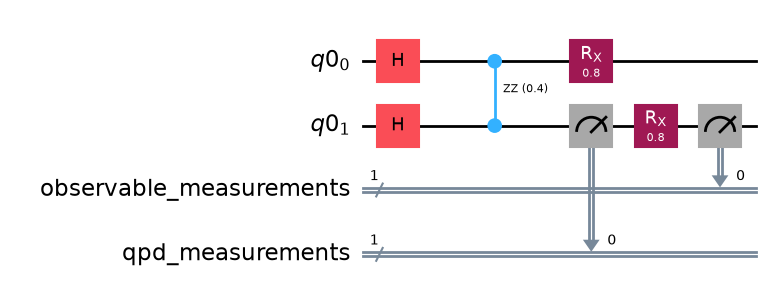

Recipe 2: B: original q2 and q3


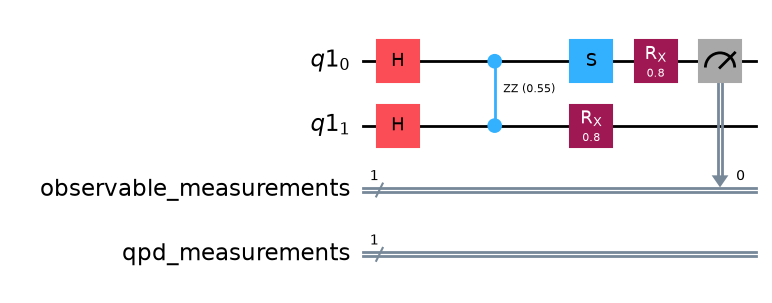

Recipe 2 coefficient: 0.24999999999999997


In [14]:
show_circuit(raw_experiments["A"][1], "Recipe 2: A: original q0 and q1")
show_circuit(raw_experiments["B"][1], "Recipe 2: B: original q2 and q3")
print("Recipe 2 coefficient:", coefficients[1])
assert generated_table.iloc[1]["A boundary"] == "Mz"
assert generated_table.iloc[1]["B boundary"] == "S"
assert np.isclose(coefficients[1], 0.25)

### One shot can contain two relevant measurements

In recipe 2, A measures its boundary qubit midway, records bit $m$,
continues with RX rotations, then measures the target Z and records
bit $a$. The shot's score is $(-1)^m(-1)^a=(-1)^{m+a}$.

**Multiply within a shot first, then average.** The two outcomes can be
correlated; multiplying their separate averages is generally wrong.
Keep both branches. There is no postselection or negative probability.

B has no cut measurement in this recipe; its final bit $b$ scores
$(-1)^b$. A and B use independent data, so their local *score averages*
can then be multiplied during reconstruction.

In [15]:
# Worked counterexample: the two bits always agree.
toy_cut_bits = np.array([0,0,1,1])
toy_final_bits = np.array([0,0,1,1])
cut_signs = 1 - 2 * toy_cut_bits
final_signs = 1 - 2 * toy_final_bits
print("Mean of within-shot products:", np.mean(cut_signs * final_signs))
print("Product of separate means:", cut_signs.mean() * final_signs.mean())

Mean of within-shot products: 1.0
Product of separate means: 0.0


### Exercise 4 · Preserve the measurement sign

Implement **student_signed_scores(cut_bits, final_bits)**. Corresponding
entries come from the same shot. Return a vector of scores. Then
calculate the supplied records' mean and explain why dropping the cut
bit changes the calculation.

**Response:** Does a negative score mean an unphysical circuit? Are
records whose cut bit is 1 thrown away?

> Your explanation:
For the supplied records the scores would be [+1,-1,-1,+1,-1,+1] with mean 0.

Negative score is not unphysical because the sign is a classical post processing; an outcome branch of the measurement is weighted by $-1$. The physical channel is $P_0\cdot P_0 + P_1\cdot P_1$; the sign turns it into the (non-CP) map the decomposition needs.

Shots with $m=1$ are kept and contribute with flipped sign.

<details><summary>Hint</summary>
The score is negative exactly when the two bits differ. Multiplication
and averaging do not generally commute.
</details>

In [ ]:
def student_signed_scores(cut_bits, final_bits):
    cut_bits= np.asarray(cut_bits, dtype=int) ## 
    final_bits=np.asarray(final_bits, dtype=int)  
    return (1 -2 * cut_bits)*(1-2 *final_bits) #(-1)**(m+a) per shot

ex4_m = np.array([0,1,0,1,1,0])
ex4_a = np.array([0,0,1,1,0,0])
ex4_answer = student_signed_scores(ex4_m, ex4_a)
if ex4_answer is None:
    report("E4", "Pending: include the mid-circuit sign")
else:
    assert np.array_equal(ex4_answer, [1,-1,-1,1,-1,1])
    assert np.array_equal(student_signed_scores(toy_cut_bits, toy_final_bits), np.ones(4))
    print("Average signed score:", np.mean(ex4_answer))
    report("E4", "Calculation checks passed: review the meaning of a negative score")

Average signed score: 0.0
E4: Calculation checks passed: review the meaning of a negative score


## 5. Check reconstruction before sampling · 10 minutes

**ExactSampler** computes exact outcome probabilities, including
intermediate measurement branches. This provides an algebraic check
for the small example. The finite-shot experiment follows in section 7.

In this single-Pauli example, all measured observable bits and all QPD
sign bits enter the score, so their combined parity gives its sign.
More general targets need a mask selecting only the observable's
support; the supplied engine handles that.

In [19]:
exact_results = {label: ExactSampler().run(circuits).result()
                 for label, circuits in raw_experiments.items()}
exact_means = {}
for label, sampled in exact_results.items():
    exact_means[label] = np.array([
        sum((1 if int(outcome).bit_count() % 2 == 0 else -1) * probability
            for outcome, probability in distribution.items())
        for distribution in sampled.quasi_dists
    ], dtype=float)
exact_official = float(reconstruct_expectation_values(
    exact_results, generated_coefficients, problem.subobservables)[0])
exact_table = generated_table.copy()
exact_table["A exact signed mean"] = exact_means["A"]
exact_table["B exact signed mean"] = exact_means["B"]
display(exact_table)
print("Addon reconstruction:", exact_official)
assert np.isclose(exact_official, diagnostic_reference, atol=1e-12)

,recipe (1-based),A boundary,B boundary,coefficient,A exact signed mean,B exact signed mean
0,1,I,I,0.933013,0.000000,0.000000
1,2,Mz,S,0.250000,0.696707,0.611564
2,3,Mz,Sdg,-0.250000,0.696707,-0.611564
3,4,S,Mz,0.250000,0.660729,0.696707
4,5,Sdg,Mz,-0.250000,-0.660729,0.696707
5,6,Z,Z,0.066987,0.000000,0.000000


Addon reconstruction: 0.44320731614817743


A bar, as in $\bar a_r$, means an average from data. The estimate is

$$\hat E=\sum_{r=1}^{6}c_r\bar a_r\bar b_r.$$

Multiply A and B averages for row 1, multiply by its coefficient, and
add the analogous contributions from rows 2–6. Coefficients are known
before measurement. Averages come from the complete local experiments,
including their sign bits.

Here preparation factors across A and B, and the target is a product of
local Z observables. These facts justify the local-product calculation.
The signed sum recovers the requested statistic; no single row creates
the original four-qubit state.

### Exercise 5 · Reconstruct without the wrapper

Implement **student_reconstruct(coefficients, a_means, b_means)**.
Return the vector of row contributions and its sum. Support arbitrary
input lengths.

**Response:** What breaks if B rows are reordered while A and
coefficients stay fixed? What statistical assumption matters when exact
means become measured averages?

> Your explanation:
The estimate is $\hat E=\sum_r c_r\,\bar a_r\,\bar b_r$, and each row only makes sense as a matched set: the A result, the B result and the coefficient all have to come from the same recipe (like A doing `Mz` while B does `S`). If you shuffle just B's rows, you end up multiplying A's result by some other recipe's B result and the wrong coefficient. The cancellations the decomposition relies on fall apart, and the answer can come out way off. Reordering is fine only if you move A, B and the coefficients together.

> On the stats side: once you're using real averages from a finite number of shots, multiplying $\bar a_r$ by $\bar b_r$ only gives the right expected value if the A and B data are independent. That means separate shots and different random seeds. The shots within each experiment also need to be independent runs of the same circuit.
<details><summary>Hint</summary>
Multiply the three arrays element by element, then sum. Preserve signs.
</details>

In [20]:
def student_reconstruct(coefficients, a_means, b_means):
    contributions = (np.asarray(coefficients, dtype=float)
                         * np.asarray(a_means, dtype=float)
                         * np.asarray(b_means, dtype=float))
    return contributions, float(contributions.sum())

ex5_answer = student_reconstruct(coefficients, exact_means["A"], exact_means["B"])
if ex5_answer is None:
    report("E5", "Pending: calculate all row contributions")
else:
    ex5_parts, ex5_estimate = ex5_answer
    assert np.allclose(ex5_parts, coefficients * exact_means["A"] * exact_means["B"])
    assert np.isclose(ex5_estimate, exact_official)
    _, probe = student_reconstruct([0.5,-0.2], [0.8,0.4], [-0.5,0.3])
    assert np.isclose(probe, -0.224)
    report("E5", "Calculation checks passed: review row matching and independence")

E5: Calculation checks passed: review row matching and independence


## 6. Make a plan with a physical-shot ledger · 10 minutes

The package wraps the addon with hardware-aware compilation, width
checks, allocation, execution, and uncertainty. **structured_cut** uses
consecutive two-qubit blocks; it is a teaching baseline, distinct from
the automatic cut finder.

Planning happens before measurement and has no access to the diagnostic
ideal answer. A direct circuit that exceeds the width limit is recorded
as unavailable and has no numerical error result.

In [21]:
try:
    plan(instance, "direct")
except InfeasiblePlan as error:
    print("Expected direct-width rejection:", error)
else:
    raise AssertionError("Four-qubit direct execution should not fit width two.")

prepared = plan(instance, "structured_cut", "coefficient")
summary = prepared.summary()
display(pd.Series({key: summary[key] for key in [
    "decision", "gate_cuts", "experiments", "maximum_experiment_width",
    "physical_shots", "maximum_qpd_overhead",
]}))
assert summary["experiments"] == 12
assert summary["physical_shots"] == 12000
assert summary["maximum_experiment_width"] <= 2

Expected direct-width rejection: direct circuit exceeds maximum experiment width


decision                      cut
gate_cuts                       1
experiments                    12
maximum_experiment_width        2
physical_shots              12000
maximum_qpd_overhead          4.0
dtype: object

**Two fragments, six recipe pairs, twelve settings.** A setting is one
specified circuit, repeated for its assigned shots. Settings could run
sequentially on one suitable device.

The coefficient allocation reserves two shots per experiment, then
distributes the remainder using coefficient magnitudes and rounding.
This fixed heuristic has no guarantee of minimum variance. Every A shot
and every B shot counts against the same request budget.
In the engine ledger below, numeric partition **0 corresponds to A**
and **1 corresponds to B** for this fixed two-block example.

,experiment index,recipe (1-based),fragment,physical width,physical shots
0,0,1,0,2,2795
1,1,2,0,2,751
2,2,3,0,2,751
3,3,4,0,2,751
4,4,5,0,2,751
5,5,6,0,2,203
6,6,1,1,2,2795
7,7,2,1,2,750
8,8,3,1,2,750
9,9,4,1,2,750


,physical shots
fragment,
0,6002
1,5998


Whole-request total: 12000
A compiled physical experiment: gates/layout may change


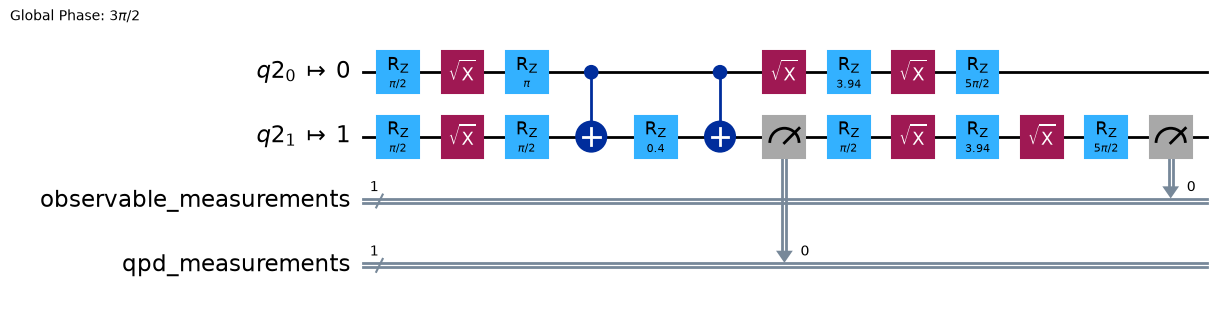

In [22]:
ledger = pd.DataFrame([
    {"experiment index": i, "recipe (1-based)": e.qpd_term+1,
     "fragment": str(e.partition), "physical width": e.circuit.num_qubits,
     "physical shots": e.shots}
    for i, e in enumerate(prepared.experiments)
])
display(ledger)
display(ledger.groupby("fragment")[["physical shots"]].sum())
print("Whole-request total:", int(ledger["physical shots"].sum()))
show_circuit(prepared.experiments[1].circuit,
             "A compiled physical experiment: gates/layout may change")

### Exercise 6 · Allocate every shot exactly once

Implement **student_equal_allocation(budget, experiment_count)** for
integer inputs with positive experiment_count. Give each setting at
least two shots, make the counts as equal as possible, and give leftover
single shots to the earliest indices. Raise ValueError if insufficient.

**Response:** Why is giving *each* of twelve settings 12,000 shots unfair
against a 12,000-shot direct run? Suggest a reason equal allocation
might differ from coefficient allocation in accuracy.

> Your explanation and prediction:
>It isn't fair because the cut plan needs all twelve settings to get one answer. Giving each one 12,000 shots means it actually uses 144,000 shots versus 12,000 for the direct run, which hides the real cost of cutting. The total shots per answer has to be the same for both.

> Splitting shots by coefficient sounds smarter, but a big coefficient doesn't always mean a row matters. Here the I/I row has the biggest coefficient but averages to 0, so it adds nothing to the answer and still gets almost half the shots. So equal allocation might actually do as well or better.
> ...

<details><summary>Hint</summary>
Check the minimum first. divmod gives a common count and a remainder.
</details>

In [24]:
def student_equal_allocation(budget, experiment_count, minimum =2): #we add the minimumn = 2
    budget, experiment_count = int(budget), int(experiment_count)
    if experiment_count <= 0:
        raise ValueError("experiment_count must be positive")
    if budget < minimum * experiment_count:
        raise ValueError(f"need at least {minimum * experiment_count} shots "
                         f"for {experiment_count} experiments, got {budget}")
    common, leftover = divmod(budget, experiment_count)
    return [common + 1 if i < leftover else common for i in range(experiment_count)]

ex6_answer = student_equal_allocation(12000, 12)
if ex6_answer is None:
    report("E6", "Pending: allocate a shared budget")
else:
    assert ex6_answer == [1000]*12
    assert student_equal_allocation(25, 12) == [3]+[2]*11
    try:
        student_equal_allocation(23, 12)
    except ValueError:
        pass
    else:
        raise AssertionError("Insufficient budgets must be rejected.")
    report("E6", "Calculation checks passed: review fair budget accounting")

E6: Calculation checks passed: review fair budget accounting


## 7. Sample the experiments · 10 minutes

Aer now executes the allocated physical shots. The engine derives a
separate reproducible random seed for each experiment. Reusing the same
sampler seed for separate batches can restart the same random stream;
reproducibility alone does not guarantee independent data.

The engine cross-checks its signed-product reconstruction against the
addon's reconstruction using the same records. Agreement verifies the
reconstruction arithmetic. Accuracy and interval coverage require
separate evaluation.

In [25]:
result = execute(instance, prepared, seed=SEED, confidence=0.95)
measured_means = np.array([row["mean"] for row in result["experiments"]])
measured_parts = np.array([
    coefficient * np.prod(measured_means[indices])
    for coefficient, indices in prepared.products
])
manual_estimate = prepared.constant + measured_parts.sum()
assert np.isclose(manual_estimate, result["estimate"])
assert result["qiskit_reconstruction_agrees"]
assert result["physical_shots"] == instance.shots
print("Finite-shot estimate:", result["estimate"])
print("Diagnostic ideal reference:", diagnostic_reference)
print("Physical shots:", result["physical_shots"])
output_directory = ROOT / "results" / "01-cut-and-reconstruct"
write_json(output_directory / "result.json", {"ideal_reference": diagnostic_reference, **result})
write_json(output_directory / "signed-ledger.json", ledger.to_dict("records"))

Finite-shot estimate: 0.4301322186601428
Diagnostic ideal reference: 0.4432073161481776
Physical shots: 12000


In [26]:
contribution_rows = []
for r, (coefficient, indices) in enumerate(prepared.products):
    contribution_rows.append({
        "recipe": r+1, "coefficient": coefficient,
        "A mean": measured_means[indices[0]], "B mean": measured_means[indices[1]],
        "contribution": measured_parts[r],
    })
display(pd.DataFrame(contribution_rows))
print("Sum of six contributions:", measured_parts.sum())

,recipe,coefficient,A mean,B mean,contribution
0,1,0.933013,-0.025403,0.007513,-0.000178
1,2,0.250000,0.651132,0.584000,0.095065
2,3,-0.250000,0.709720,-0.597333,0.105985
3,4,0.250000,0.653795,0.720000,0.117683
4,5,-0.250000,-0.659121,0.677333,0.111611
5,6,0.066987,0.034483,-0.014778,-0.000034


Sum of six contributions: 0.4301322186601428


### Read one row slowly

Recipe 2 has coefficient +0.25. Its A mean includes the mid-circuit and
final observable signs; its B mean includes the final observable sign.
Multiply those two means and 0.25 to get this row's contribution.
The full answer is the sum of all six contributions.

We can recover positive/negative **score counts** from each recorded
mean: $n_+=(n+n\bar x)/2$, $n_-=(n-n\bar x)/2$. These count the
combined ±1 scores. The two individual A bits cannot be recovered
from these counts.

In [27]:
row2_weight, row2_indices = prepared.products[1]
row2_counts = []
for name, index in zip(["A","B"], row2_indices):
    n = prepared.experiments[index].shots
    average = measured_means[index]
    positive = int(round(n*(1+average)/2))
    negative = n-positive
    assert np.isclose((positive-negative)/n, average)
    row2_counts.append({"fragment": name, "positive scores": positive,
                        "negative scores": negative, "shots": n, "mean": average})
display(pd.DataFrame(row2_counts))
print("Row 2 contribution:", row2_weight*np.prod(measured_means[row2_indices]))

,fragment,positive scores,negative scores,shots,mean
0,A,620,131,751,0.651132
1,B,594,156,750,0.584000


Row 2 contribution: 0.0950652463382157


## 8. What does uncertainty cover? · 10 minutes

The reported standard error is a **plug-in approximation**. The
independent-product variance identity retains terms a first-order
approximation can miss:

$$\operatorname{Var}(XY)=\mu_X^2v_Y+\mu_Y^2v_X+v_Xv_Y.$$

This is exact for independent variables with their true moments.
Substituting estimated moments does not guarantee calibrated intervals.

The separate conservative interval combines Hoeffding bounds for bounded
local scores, a union bound across experiments, and interval arithmetic
through the signed products. Allocation is fixed; shots within each
experiment must be independent and identically distributed.
Product-unbiasedness also needs independent fragment data.

The interval covers sampling uncertainty in the **reconstructed noisy
quantity**. It does not bound hardware bias relative to an ideal circuit.
Here synthetic error rates are zero, so those quantities coincide. A 95%
procedure describes repeated-data coverage; it does not assign a 95%
posterior probability to this particular interval.

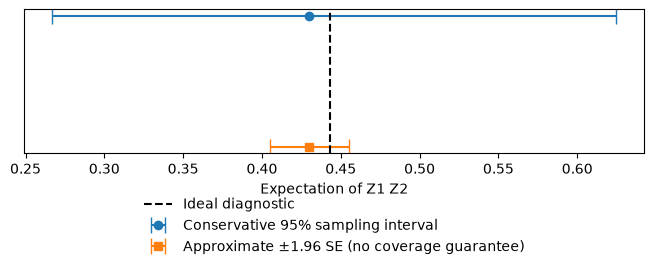

Conservative interval: [0.267103510176732, 0.6246456837623029]


In [28]:
lower, upper = result["sampling_interval"]
estimate = result["estimate"]
approx_se = result["sampling_standard_error_approx"]
fig, ax = plt.subplots(figsize=(8,3))
ax.errorbar(estimate, 1, xerr=[[estimate-lower],[upper-estimate]],
            fmt="o", capsize=6, label="Conservative 95% sampling interval")
ax.errorbar(estimate, 0, xerr=1.96*approx_se, fmt="s", capsize=6,
            label="Approximate ±1.96 SE (no coverage guarantee)")
ax.axvline(diagnostic_reference, color="black", linestyle="--", label="Ideal diagnostic")
ax.set_yticks([])
ax.set_xlabel("Expectation of Z1 Z2")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.22), frameon=False)
fig.subplots_adjust(bottom=0.4)
display(fig)
plt.close(fig)
print("Conservative interval:", [lower, upper])

### Exercise 7 · Interpret the error bar

Fill the three response strings below.

1. A noisy estimate has a narrow interval that excludes the ideal
   reference. Give a plausible explanation without claiming one run
   identifies the cause.
2. Our interval contains the ideal reference. What does this observation
   establish, and what does it fail to establish?
3. With a larger shot budget, which error could shrink and which might
   remain? Mention the effect of fixed overhead.

<details><summary>Hint</summary>
Distinguish sampling variation, noise bias, empirical coverage, and
performance across instances. More shots do not fix a wrong formula.
</details>

In [29]:
ex7_answers = {
    "narrow_but_misses_ideal": (
        "The interval only covers sampling error, not device noise. Noise can shift the "
        "result away from the ideal value, so with lots of shots you get a tight interval "
        "around the wrong number. Noise bias is the likely cause, but one run can't prove "
        "it: it could also just be one of the 5% of intervals that miss, or a bug."),
    "one_interval_contains_reference": (
        "It shows this run agrees with the ideal value and nothing obviously broke. It "
        "doesn't show the method really has 95% coverage (that needs many runs), that it "
        "works on other circuits or with noise, or that it beats other plans. This "
        "interval is also very conservative, so it was likely to contain the value anyway."),
    "more_shots": (
        "More shots shrink the random sampling error (4x the shots halves it). They don't "
        "fix noise bias or mistakes, so you just get more precise around a biased answer. "
        "Cutting always needs about gamma^2 times more shots than a direct run for the same "
        "precision, and more shots never removes that penalty."),
}
if all(isinstance(v,str) and v.strip() for v in ex7_answers.values()):
    report("E7", "Responses supplied: self/peer review required, not auto-graded")
else:
    report("E7", "Pending: write all three uncertainty explanations")

E7: Responses supplied: self/peer review required, not auto-graded


## 9. Compare under matched conditions · 15–20 minutes

First allow width four, making direct execution feasible. Keep the same
circuit, target, noise profile, and **12,000-shot budget per request**.
Direct and cut requests spend separate budgets. Each repetition is
another request with its own 12,000-shot allowance.

Compare direct execution, cutting with equal allocation, and cutting
with coefficient allocation. Four repetitions illustrate variation on
this circuit. A broader comparison needs more circuits and repetitions.
Keep width-infeasible direct plans marked as unavailable.

In [30]:
comparable_instance = replace(instance, max_width=4,
                              instance_id="workbook-one-width4-comparison")
comparison_plans = {
    "direct": plan(comparable_instance, "direct", "equal"),
    "cut_equal": plan(comparable_instance, "structured_cut", "equal"),
    "cut_coefficient": plan(comparable_instance, "structured_cut", "coefficient"),
}
display(pd.DataFrame([
    {"method": name, "shots per request": candidate.summary()["physical_shots"],
     "max physical width": candidate.summary()["maximum_experiment_width"],
     "logical fragment widths": candidate.metadata["logical_fragment_widths"],
     "experiment settings": candidate.summary()["experiments"]}
    for name, candidate in comparison_plans.items()
]))
# Planning alone spends no physical shots.

,method,shots per request,max physical width,logical fragment widths,experiment settings
0,direct,12000,4,[4],1
1,cut_equal,12000,4,[2],12
2,cut_coefficient,12000,4,[2],12


### Exercise 8 · Run and explain a fair comparison

Notice both width columns above. Compiling against the width-four
hardware graph can pad a two-qubit logical fragment with unused physical
wires. The reported physical width counts the returned circuit's wires;
the logical fragment sizes still describe the partition. Our earlier
width-two plan demonstrated that those fragments can also run within
a strict two-qubit limit.

Implement **student_comparison(base, plans, seeds)**. Execute one full
request per method and seed. Return a DataFrame with columns **method,
repetition, estimate, physical_shots**. Repetitions are numbered from 0.
Derive a distinct reproducible sampler seed per method/repetition, for
example with children from numpy.random.SeedSequence.

Do not pass an ideal reference to planning or execution. The check cell
computes errors afterward. Four repeats × three methods × 12,000 shots
means **144,000 shots across twelve requests**.

**Response:** Predict an outcome before running. Explain the observed
RMSEs, width tradeoff, and at least two reasons they do not establish
a generally superior planner. Suggest one follow-up experiment.

> Prediction: With no noise, all three methods should land on the right answer on average, so the only difference is random scatter. I expect direct to be the most accurate, since it doesn't pay the cutting overhead, and the two cut versions to be a bit worse.
>
Direct came out best (RMSE 0.0106), then cut with equal shots (0.0142), then cut with coefficient shots (0.0198). Cutting cost less extra error than the $\gamma^2=4$ bound suggests. Coefficient allocation did worse, probably because it gives almost half the shots to the I/I row, which contributes nothing here. The tradeoff is that direct needs a 4-qubit device, while cutting runs on 2 qubits but needs 12 circuits and more shots.
>
> This doesn't prove one planner is better in general. 4 repetitions is very few, so the ranking could flip with other seeds. It's also one small circuit with no noise, and with real noise the methods could behave differently. As a follow-up, I'd rerun with many more repetitions, several different circuits, and a noise model.

<details><summary>Hint</summary>
execute(base, candidate, seed=...) returns the estimate and shot count.
Keep every result. Compute RMSE by squaring the errors, averaging them,
and taking the square root. Execute each request in your function.
</details>

In [31]:
def student_comparison(base, plans, seeds):
    rows = []
    method_names = list(plans)
    for repetition, seed in enumerate(seeds):
        children = np.random.SeedSequence(seed).spawn(len(method_names))
        for method, child in zip(method_names, children):
            sampler_seed = int(child.generate_state(1, dtype=np.uint32)[0])
            outcome = execute(base, plans[method], seed=sampler_seed)
            rows.append({"method": method, "repetition": repetition,
                            "estimate": outcome["estimate"],
                            "physical_shots": outcome["physical_shots"],
                            "sampler_seed": sampler_seed,
                            "approx_se": outcome["sampling_standard_error_approx"],
                            "interval_low": outcome["sampling_interval"][0],
                            "interval_high": outcome["sampling_interval"][1]})
    return pd.DataFrame(rows)

study_seeds = [SEED+100+i for i in range(4)]
ex8_frame = student_comparison(comparable_instance, comparison_plans, study_seeds)
if ex8_frame is None:
    report("E8", "Pending: execute a matched comparison and discuss limitations")
else:
    assert {"method","repetition","estimate","physical_shots"} <= set(ex8_frame.columns)
    assert len(ex8_frame) == 12
    assert set(ex8_frame["method"]) == set(comparison_plans)
    assert not ex8_frame.duplicated(["method","repetition"]).any()
    assert set(ex8_frame["repetition"]) == set(range(4))
    assert (ex8_frame.groupby("method").size() == 4).all()
    assert np.isfinite(ex8_frame["estimate"]).all()
    assert (ex8_frame["physical_shots"] == comparable_instance.shots).all()
    scored = ex8_frame.assign(squared_error=(
        ex8_frame["estimate"]-diagnostic_reference)**2)
    display(scored.groupby("method").agg(
        mean_squared_error=("squared_error","mean"),
        repetitions=("repetition","count"),
    ).assign(RMSE=lambda frame: np.sqrt(frame["mean_squared_error"])))
    print("Study-wide physical shots:", int(ex8_frame["physical_shots"].sum()))
    report("E8", "Study completed: interpretation still needs scientific review")

,mean_squared_error,repetitions,RMSE
method,,,
cut_coefficient,0.000391,4,0.019779
cut_equal,0.000202,4,0.014205
direct,0.000112,4,0.010568


Study-wide physical shots: 144000
E8: Study completed: interpretation still needs scientific review


## Keep these distinctions in your submission

- A **fragment** is a local circuit group; a **recipe** chooses cut
  actions; a **setting** instantiates a circuit; a **shot** executes it.
- Negative coefficients and recorded signs enter classical arithmetic.
  They are not negative probabilities.
- Exact QPD enumeration does not remove measurement uncertainty.
- A planner can choose cuts, mapping, preprocessing, allocation, and
  valid alternative decompositions. Changing signs or dropping rows
  arbitrarily breaks exact equivalence.
- $\gamma^2$ describes possible statistical amplification. It is not a
  measured speedup, setting count, or exact variance for this estimator.

Revisit the [official width-reduction tutorial](https://qiskit.github.io/qiskit-addon-cutting/tutorials/01_gate_cutting_to_reduce_circuit_width.html),
[exact-coefficient guide](https://qiskit.github.io/qiskit-addon-cutting/how-tos/how_to_generate_exact_sampling_coefficients.html),
and [implemented decomposition](https://qiskit.github.io/qiskit-addon-cutting/_modules/qiskit_addon_cutting/qpd/decompositions.html).
The signs used here agree with addon 0.10.0 source and independent
matrix checks. The introductory prose RZZ table uses opposite mixed signs
under the same stated convention. Use the implemented decomposition and
verify conventions when comparing tables.

## B1

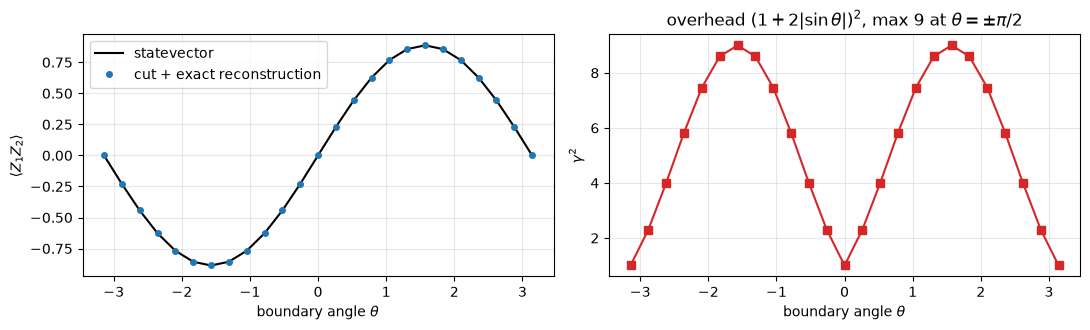

Max |reconstructed - statevector| over the sweep: 6.661338147750939e-16
Settings per angle: [2, 12] (fewer where coefficients vanish)


In [35]:
##Esto fue en su mayor parte hecho por ia
##This pasrt was made almost entirely by AI

sweep = []
for angle in np.linspace(-np.pi, np.pi, 25):
    circuit = make_worked_circuit(angle)
    prob = partition_problem(circuit, partition_labels=labels, observables=PauliList(["IZZI"]))
    exps, coefs = generate_cutting_experiments(prob.subcircuits, prob.subobservables, num_samples=np.inf)
    exact = {k: ExactSampler().run(v).result() for k, v in exps.items()}
    reconstructed = float(reconstruct_expectation_values(exact, coefs, prob.subobservables)[0])
    ideal = float(Statevector.from_instruction(circuit).expectation_value(target).real)
    sweep.append({"theta": angle, "reconstructed": reconstructed, "statevector": ideal,
                  "closed_form": np.sin(angle)*np.cos(0.8)*np.sin(0.8)*(np.cos(0.4)+np.cos(0.55)),
                  "gamma_squared": QPDBasis.from_instruction(RZZGate(angle)).overhead,
                  "settings": 2 * len(coefs)})
sweep = pd.DataFrame(sweep)
assert np.allclose(sweep["reconstructed"], sweep["statevector"], atol=1e-10)
assert np.allclose(sweep["closed_form"], sweep["statevector"], atol=1e-10)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.plot(sweep["theta"], sweep["statevector"], "k-", label="statevector")
a1.plot(sweep["theta"], sweep["reconstructed"], "o", ms=4, label="cut + exact reconstruction")
a1.set_xlabel(r"boundary angle $\theta$"); a1.set_ylabel(r"$\langle Z_1Z_2\rangle$"); a1.legend(); a1.grid(alpha=.3)
a2.plot(sweep["theta"], sweep["gamma_squared"], "s-", color="C3")
a2.set_xlabel(r"boundary angle $\theta$"); a2.set_ylabel(r"$\gamma^2$"); a2.grid(alpha=.3)
a2.set_title(r"overhead $(1+2|\sin\theta|)^2$, max 9 at $\theta=\pm\pi/2$")
fig.tight_layout(); display(fig); plt.close(fig)
print("Max |reconstructed - statevector| over the sweep:",
      float(np.max(np.abs(sweep["reconstructed"] - sweep["statevector"]))))
print("Settings per angle:", sorted(set(sweep["settings"])), "(fewer where coefficients vanish)")

## B2

In [36]:
noisy_profile = HardwareProfile(name="synthetic-noisy", topology="line",
                                one_qubit_error=0.002, two_qubit_error=0.02, readout_error=0.02)
noisy_instance = replace(comparable_instance, hardware=noisy_profile,
                         instance_id="workbook-one-width4-noisy")
noisy_plans = {
    "direct": plan(noisy_instance, "direct", "equal"),
    "cut_coefficient": plan(noisy_instance, "structured_cut", "coefficient"),
}
noisy_rows = []
for repetition, seed in enumerate([SEED + 500 + i for i in range(4)]):
    for method, candidate in noisy_plans.items():
        out = execute(noisy_instance, candidate, seed=seed + 17 * len(method))
        noisy_rows.append({"method": method, "repetition": repetition, "estimate": out["estimate"],
                           "approx_se": out["sampling_standard_error_approx"],
                           "interval_low": out["sampling_interval"][0],
                           "interval_high": out["sampling_interval"][1]})
noisy_frame = pd.DataFrame(noisy_rows)
noisy_frame["contains_ideal"] = ((noisy_frame["interval_low"] <= diagnostic_reference)
                                 & (diagnostic_reference <= noisy_frame["interval_high"]))
display(noisy_frame)
display(noisy_frame.assign(error=noisy_frame["estimate"] - diagnostic_reference)
        .groupby("method").agg(mean_estimate=("estimate", "mean"), mean_error=("error", "mean"),
                               spread=("estimate", "std"), mean_se=("approx_se", "mean")))
print("Ideal diagnostic:", diagnostic_reference)

,method,repetition,estimate,approx_se,interval_low,interval_high,contains_ideal
0,direct,0,0.346167,0.008565,0.321371,0.370962,False
1,cut_coefficient,0,0.347994,0.012388,0.203672,0.527587,True
2,direct,1,0.355667,0.008532,0.330871,0.380462,False
3,cut_coefficient,1,0.378316,0.012612,0.226879,0.564876,True
4,direct,2,0.362000,0.008510,0.337205,0.386795,False
5,cut_coefficient,2,0.369911,0.012579,0.219257,0.552078,True
6,direct,3,0.382833,0.008434,0.358038,0.407629,False
7,cut_coefficient,3,0.374322,0.012555,0.224611,0.558091,True


,mean_estimate,mean_error,spread,mean_se
method,,,,
cut_coefficient,0.367635,-0.075572,0.013537,0.012533
direct,0.361667,-0.081541,0.015539,0.008510


Ideal diagnostic: 0.4432073161481776


## B3

In [37]:
from copy import deepcopy
from scipy.optimize import minimize
from wqcc_planner.statistics import allocate_shots

products = prepared.products
n_exp = len(prepared.experiments)

def full_variance(shots, means):
    shots = np.asarray(shots, dtype=float)
    v = (1 - np.square(means)) / shots
    return float(sum(c**2 * ((means[a]**2 + v[a]) * (means[b]**2 + v[b]) - means[a]**2 * means[b]**2)
                     for c, (a, b) in products))

def optimal_allocation(means, budget, minimum=2):
    # Minimize the full product variance subject to sum(n) == budget, n >= minimum.
    # Shots are parametrized as n = minimum + (budget - minimum*k) * softmax(z), so the
    # constraints hold automatically and an unconstrained optimizer can be used.
    # The objective is rescaled by the budget (variances are ~1e-4).
    means = np.clip(np.asarray(means, dtype=float), -0.999, 0.999)
    free = budget - minimum * n_exp
    def shots_from(z):
        p = np.exp(z - z.max())
        return minimum + free * p / p.sum()
    res = minimize(lambda z: budget * full_variance(shots_from(z), means),
                   np.zeros(n_exp), method="L-BFGS-B")
    target = shots_from(res.x)
    # integer rounding that spends exactly `budget`
    shots = np.floor(target).astype(int)
    order = np.argsort(-(target - shots))
    shots[order[:budget - shots.sum()]] += 1
    assert shots.sum() == budget and shots.min() >= minimum
    return shots.tolist()

# Exact per-experiment means, used ONLY to predict/score each rule.
exact_by_experiment = np.array([exact_means["A" if str(e.partition) in ("0", "A") else "B"][e.qpd_term]
                                for e in prepared.experiments])
rules = {
    "equal": allocate_shots([1.0] * n_exp, 12000),
    "coefficient (engine)": [e.shots for e in prepared.experiments],
    "optimized (oracle means)": optimal_allocation(exact_by_experiment, 12000),
}
display(pd.DataFrame({name: {"predicted SE": np.sqrt(full_variance(s, exact_by_experiment)),
                             "shots on I/I + Z/Z rows": sum(s[i] for i, e in enumerate(prepared.experiments)
                                                            if e.qpd_term in (0, 5)),
                             "min shots": min(s), "max shots": max(s)}
                      for name, s in rules.items()}).T)
display(pd.DataFrame(rules, index=[f"recipe {e.qpd_term+1} / frag {e.partition}"
                                   for e in prepared.experiments]).T)

def run_with_shots(shots, seed):
    candidate = deepcopy(prepared)
    for e, n in zip(candidate.experiments, shots):
        e.shots = int(n)
    return execute(instance, candidate, seed=seed)

def pilot_then_optimized(seed, pilot_budget=1200):
    pilot_shots = np.array(allocate_shots([1.0] * n_exp, pilot_budget))
    pilot = run_with_shots(pilot_shots, seed)
    pilot_means = np.array([row["mean"] for row in pilot["experiments"]])
    main_shots = np.array(optimal_allocation(pilot_means, 12000 - pilot_budget))
    main = run_with_shots(main_shots, seed + 1)
    main_means = np.array([row["mean"] for row in main["experiments"]])
    pooled = (pilot_shots * pilot_means + main_shots * main_means) / (pilot_shots + main_shots)
    estimate = prepared.constant + sum(c * np.prod(pooled[idx]) for c, idx in products)
    return estimate, pilot["physical_shots"] + main["physical_shots"]

repeats = 50
allocation_rows = []
for r in range(repeats):
    s = SEED + 1000 + 10 * r
    allocation_rows.append({"rule": "equal", "estimate": run_with_shots(rules["equal"], s)["estimate"]})
    allocation_rows.append({"rule": "coefficient (engine)",
                            "estimate": run_with_shots(rules["coefficient (engine)"], s + 3)["estimate"]})
    est, used = pilot_then_optimized(s + 5)
    assert used == 12000
    allocation_rows.append({"rule": "pilot + optimized", "estimate": est})
allocation_frame = pd.DataFrame(allocation_rows)
allocation_summary = (allocation_frame.assign(sq=(allocation_frame["estimate"] - diagnostic_reference) ** 2)
    .groupby("rule").agg(repetitions=("estimate", "count"), mean_estimate=("estimate", "mean"),
                         empirical_SD=("estimate", "std"), RMSE=("sq", lambda x: float(np.sqrt(np.mean(x))))))
display(allocation_summary)

,predicted SE,shots on I/I + Z/Z rows,min shots,max shots
equal,0.011192,4000.0,1000.0,1000.0
coefficient (engine),0.012884,5996.0,203.0,2795.0
optimized (oracle means),0.009758,1104.0,81.0,1511.0


,recipe 1 / frag 0,recipe 2 / frag 0,recipe 3 / frag 0,recipe 4 / frag 0,recipe 5 / frag 0,recipe 6 / frag 0,recipe 1 / frag 1,recipe 2 / frag 1,recipe 3 / frag 1,recipe 4 / frag 1,recipe 5 / frag 1,recipe 6 / frag 1
equal,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
coefficient (engine),2795,751,751,751,751,203,2795,750,750,750,750,203
optimized (oracle means),471,1203,1203,1434,1434,81,471,1511,1511,1300,1300,81


,repetitions,mean_estimate,empirical_SD,RMSE
rule,,,,
coefficient (engine),50,0.445444,0.010966,0.011084
equal,50,0.443690,0.012104,0.011992
pilot + optimized,50,0.444251,0.011534,0.011465


In [34]:
display(pd.DataFrame({"exercise": list(progress), "status": list(progress.values())}))
pending = [name for name,status in progress.items() if status.startswith("Pending")]
print("Still pending:", ", ".join(pending) if pending else "No blank exercises detected.")
print("Written reasoning and scientific claims still need your review.")

,exercise,status
0,E1,Calculation checks passed: review your written...
1,E2,Calculation checks passed: review your partiti...
2,E3,Calculation checks passed: review the overhead...
3,E4,Calculation checks passed: review the meaning ...
4,E5,Calculation checks passed: review row matching...
5,E6,Calculation checks passed: review fair budget ...
6,E7,"Responses supplied: self/peer review required,..."
7,E8,Study completed: interpretation still needs sc...


Still pending: No blank exercises detected.
Written reasoning and scientific claims still need your review.


## What to keep, and where to go next

Save your responses, the generated recipe table, physical-shot ledger,
and comparison table if completed. Mark unfinished tasks and explain
any failed checks.

Explain aloud how recipe 2 becomes one contribution: mention its two
fragment experiments, A's within-shot sign, its coefficient, and the
five other contributions. Then explain why running directly must remain
a possible planner decision.

This workbook covers one circuit and one observable. The challenge context
describes the broader planner task. Use this worked example as evidence
for its own reconstruction and resource accounting, and state its limits
when discussing a submission.

Return to the [prompt guide](planner-prompt.md) for the challenge context and optional references.